	Predicting Stock Market Prices	Apply first-order differencing and thoroughly validate the stationarity of the transformed TSLA time series through visualization (ACF, PACF plots) and statistical testing (ADF, KPSS), ensuring readiness for time series modeling.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load dataset and sort chronologically
df = pd.read_csv('TSLA_cleaned_data.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

# Apply first-order differencing (d = 1)
df['Close_Diff1'] = df['Close'].diff(1)
diff_series = df['Close_Diff1'].dropna()

print(f"Original Series Length   : {len(df)} observations")
print(f"Differenced Series Length: {len(diff_series)} observations (1 initial NaN dropped)")
print(f"Diff1 Summary -> Mean: ${diff_series.mean():.4f} | Std: ${diff_series.std():.4f} | Min: ${diff_series.min():.2f} | Max: ${diff_series.max():.2f}")
df[['Date', 'Close', 'Close_Diff1']].head()

Original Series Length   : 100 observations
Differenced Series Length: 99 observations (1 initial NaN dropped)
Diff1 Summary -> Mean: $0.1310 | Std: $4.0686 | Min: $-10.53 | Max: $11.98


,Date,Close,Close_Diff1
0,2025-01-02,381.88,NaN
1,2025-01-03,376.36,-5.52
2,2025-01-06,380.68,4.32
3,2025-01-07,386.06,5.38
4,2025-01-08,375.53,-10.53


In [3]:
def validate_stationarity(series, label):
    clean = series.dropna()
    adf_stat, adf_p, adf_lags, _, adf_crit, _ = adfuller(clean, autolag='AIC')
    kpss_c_stat, kpss_c_p, kpss_c_lags, kpss_c_crit = kpss(clean, regression='c', nlags='auto')
    kpss_ct_stat, kpss_ct_p, kpss_ct_lags, kpss_ct_crit = kpss(clean, regression='ct', nlags='auto')
    
    is_stationary = (adf_p < 0.05) and (kpss_c_p >= 0.05) and (kpss_ct_p >= 0.05)
    return {
        'Series': label,
        'ADF_Stat': round(adf_stat, 4),
        'ADF_pVal': round(adf_p, 4),
        'ADF_5%_Crit': round(adf_crit['5%'], 4),
        'KPSS_Level_Stat': round(kpss_c_stat, 4),
        'KPSS_Level_pVal': round(kpss_c_p, 4),
        'KPSS_Trend_Stat': round(kpss_ct_stat, 4),
        'KPSS_Trend_pVal': round(kpss_ct_p, 4),
        'Modeling_Ready': 'YES (Stationary I(0))' if is_stationary else 'NO (Non-Stationary I(1))'
    }

validation_table = pd.DataFrame([
    validate_stationarity(df['Close'], 'Raw TSLA Close (d=0)'),
    validate_stationarity(df['Close_Diff1'], '1st-Order Differenced Close (d=1)')
])

print("--- ADF & KPSS Stationarity Validation Table ---")
print(validation_table.to_string(index=False))

# Ljung-Box Test on Differenced Series (checks remaining serial autocorrelation)
lb_test = acorr_ljungbox(diff_series, lags=[5, 10, 15], return_df=True)
print("\n--- Ljung-Box Serial Autocorrelation Check (d=1) ---")
print(lb_test.round(4).to_string())

--- ADF & KPSS Stationarity Validation Table ---
                           Series  ADF_Stat  ADF_pVal  ADF_5%_Crit  KPSS_Level_Stat  KPSS_Level_pVal  KPSS_Trend_Stat  KPSS_Trend_pVal           Modeling_Ready
             Raw TSLA Close (d=0)   -1.5451    0.5111      -2.8912           1.2578             0.01           0.3450             0.01 NO (Non-Stationary I(1))
1st-Order Differenced Close (d=1)   -9.4303    0.0000      -2.8915           0.1297             0.10           0.0701             0.10    YES (Stationary I(0))

--- Ljung-Box Serial Autocorrelation Check (d=1) ---
    lb_stat  lb_pvalue
5    1.7492     0.8826
10   5.9652     0.8182
15   9.6562     0.8408


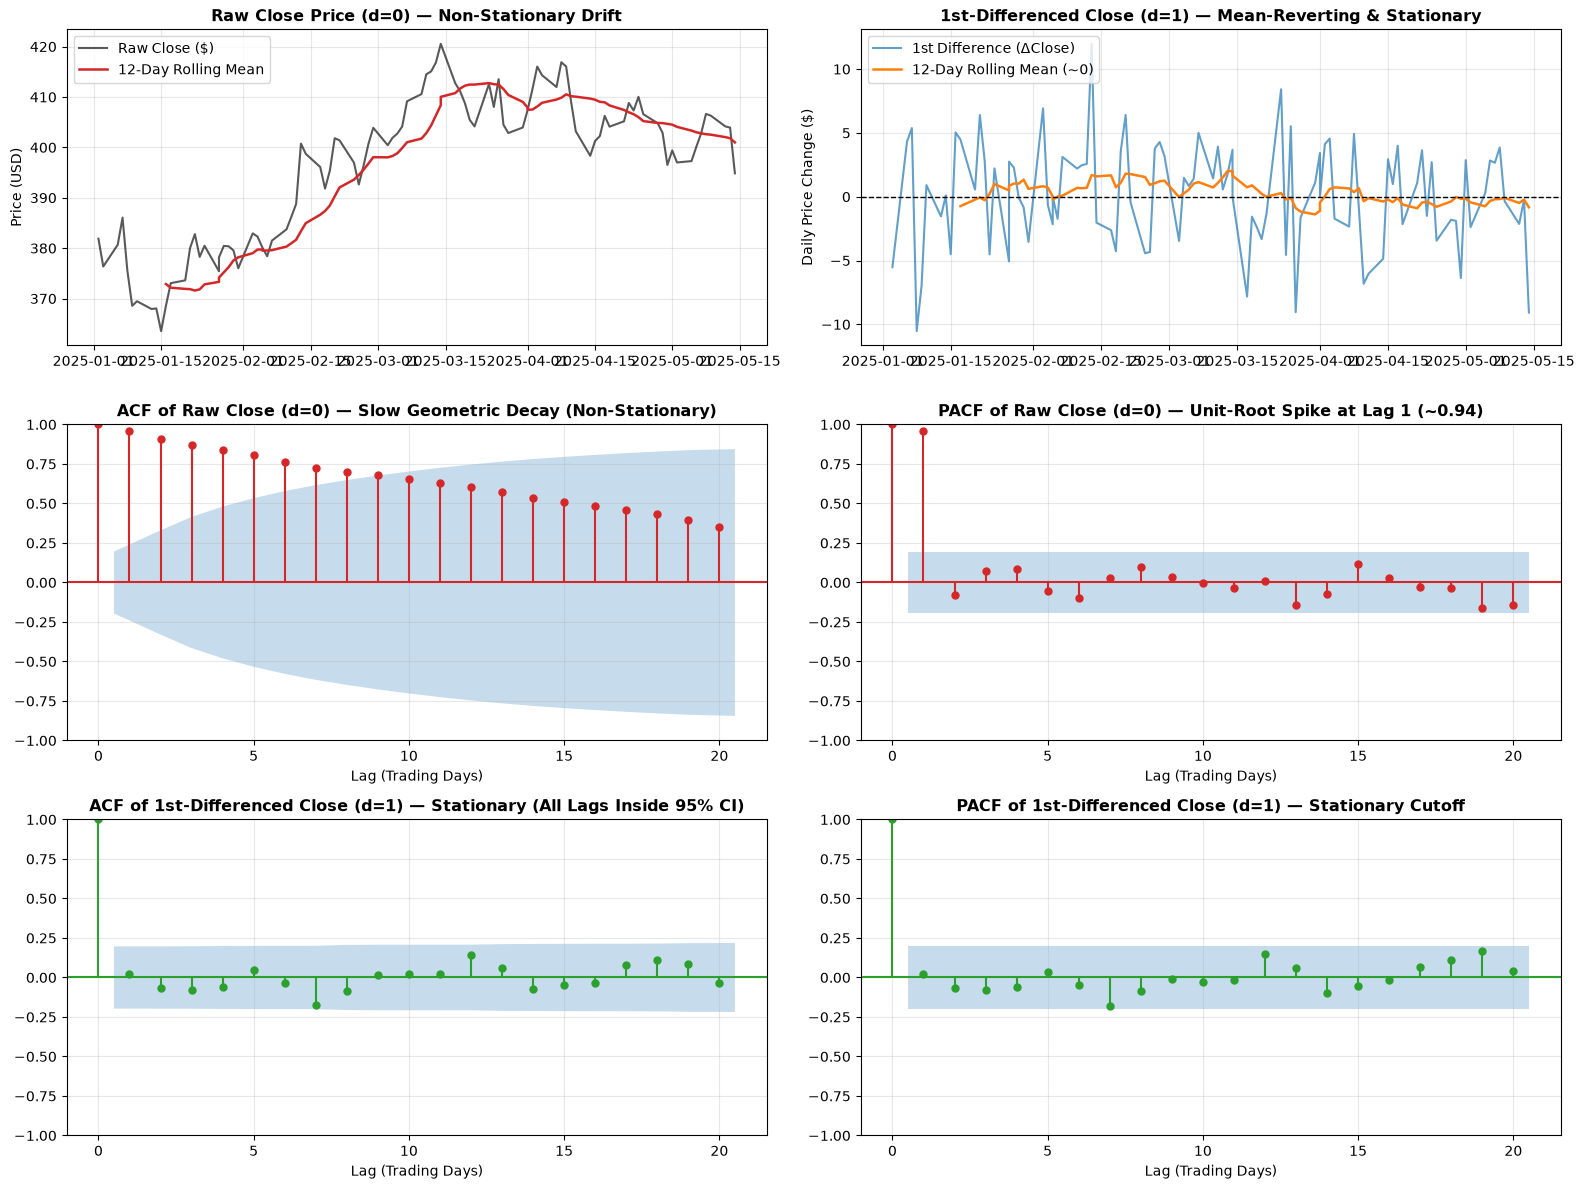

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(16, 12))

# Row 1: Raw Close vs. 1st-Order Differenced Close (Mean & Variance Stability)
axes[0, 0].plot(df['Date'], df['Close'], color='black', alpha=0.65, label='Raw Close ($)')
axes[0, 0].plot(df['Date'], df['Close'].rolling(12).mean(), color='#d62728', linewidth=1.8, label='12-Day Rolling Mean')
axes[0, 0].set_title('Raw Close Price (d=0) — Non-Stationary Drift', fontsize=11.5, fontweight='bold')
axes[0, 0].set_ylabel('Price (USD)')
axes[0, 0].legend(loc='upper left')
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(df['Date'], df['Close_Diff1'], color='#1f77b4', alpha=0.7, label='1st Difference (ΔClose)')
axes[0, 1].plot(df['Date'], df['Close_Diff1'].rolling(12).mean(), color='#ff7f0e', linewidth=1.8, label='12-Day Rolling Mean (~0)')
axes[0, 1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[0, 1].set_title('1st-Differenced Close (d=1) — Mean-Reverting & Stationary', fontsize=11.5, fontweight='bold')
axes[0, 1].set_ylabel('Daily Price Change ($)')
axes[0, 1].legend(loc='upper left')
axes[0, 1].grid(True, alpha=0.3)

# Row 2: ACF & PACF of Raw Close (d=0) — Slow Decay & Lag-1 Dominance
plot_acf(df['Close'], lags=20, ax=axes[1, 0], color='#d62728', vlines_kwargs={'colors': '#d62728'})
axes[1, 0].set_title('ACF of Raw Close (d=0) — Slow Geometric Decay (Non-Stationary)', fontsize=11.5, fontweight='bold')
axes[1, 0].set_xlabel('Lag (Trading Days)')
axes[1, 0].grid(True, alpha=0.3)

plot_pacf(df['Close'], lags=20, method='ywm', ax=axes[1, 1], color='#d62728', vlines_kwargs={'colors': '#d62728'})
axes[1, 1].set_title('PACF of Raw Close (d=0) — Unit-Root Spike at Lag 1 (~0.94)', fontsize=11.5, fontweight='bold')
axes[1, 1].set_xlabel('Lag (Trading Days)')
axes[1, 1].grid(True, alpha=0.3)

# Row 3: ACF & PACF of 1st-Differenced Close (d=1) — Rapid Cutoff Inside 95% CI
plot_acf(diff_series, lags=20, ax=axes[2, 0], color='#2ca02c', vlines_kwargs={'colors': '#2ca02c'})
axes[2, 0].set_title('ACF of 1st-Differenced Close (d=1) — Stationary (All Lags Inside 95% CI)', fontsize=11.5, fontweight='bold')
axes[2, 0].set_xlabel('Lag (Trading Days)')
axes[2, 0].grid(True, alpha=0.3)

plot_pacf(diff_series, lags=20, method='ywm', ax=axes[2, 1], color='#2ca02c', vlines_kwargs={'colors': '#2ca02c'})
axes[2, 1].set_title('PACF of 1st-Differenced Close (d=1) — Stationary Cutoff', fontsize=11.5, fontweight='bold')
axes[2, 1].set_xlabel('Lag (Trading Days)')
axes[2, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()